# Partial Dependence & ICE Plot

**Family:** Multivariate & ML &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Multivariate & ML:* Explore many variables at once and explain or diagnose statistical and machine-learning models.

## Design purpose

Shows how a model's prediction changes as one feature varies while the others stay at their observed values. Thin ICE lines trace individual cases and the bold line is their average (partial dependence), which exposes the shape of a feature's effect: linear, threshold, plateau or interaction.

## When to use

- Explain the shape of a feature's effect in a black-box model (gradient boosting, random forest)
- Check for thresholds or saturation that a linear model would miss
- Spot interactions (ICE lines that are not parallel)

## Avoid when

- The feature is strongly correlated with others (the model gets evaluated on impossible combinations)
- You need effects for more than ~2 features at once

## Alternatives

- SHAP dependence plot
- Accumulated local effects (ALE) plot, which copes better with correlated features

## Design tips

- Add a rug of the observed values so readers see where data is thin
- Center the ICE lines (subtract each line's starting value) if levels vary a lot
- Keep ICE lines thin and gray, and the average line bold

## Example

A gradient-boosting model of disease progression one year after baseline, fitted to the real Diabetes dataset bundled with scikit-learn (load_diabetes, 442 patients, standardized features). The panels show BMI and the serum triglycerides measure (s5).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from sklearn.datasets import load_diabetes
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.inspection import PartialDependenceDisplay

### Data

In [2]:
diab = load_diabetes(as_frame=True)
X, y = diab.data, diab.target
model = GradientBoostingRegressor(n_estimators=300, max_depth=2, learning_rate=0.05,
                                  random_state=0).fit(X, y)
print(f"R² on training data: {model.score(X, y):.2f}")
X.describe().loc[["mean", "std"], ["bmi", "s5"]].round(3)

R² on training data: 0.72


,bmi,s5
mean,-0.000,0.000
std,0.048,0.048


### Plot

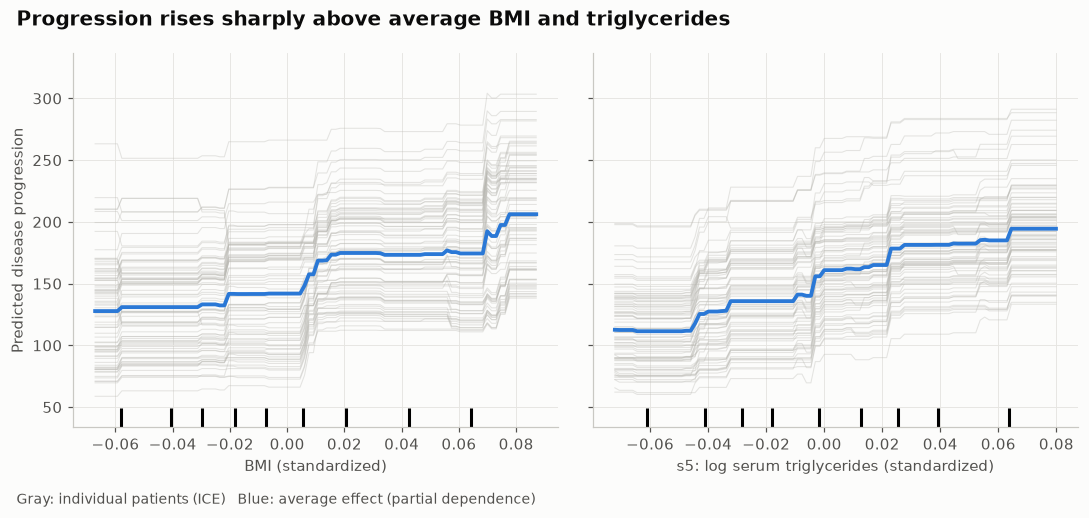

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True)
PartialDependenceDisplay.from_estimator(
    model, X, ["bmi", "s5"], kind="both", subsample=80, random_state=0, ax=axes,
    ice_lines_kw={"color": "#b8b7b1", "alpha": 0.35, "linewidth": 0.7},
    pd_line_kw={"color": PALETTE[0], "linewidth": 2.5, "linestyle": "-"})
for ax, name in zip(axes, ["BMI (standardized)", "s5: log serum triglycerides (standardized)"]):
    ax.set_xlabel(name)
    ax.grid(True, color="#e6e5e1", linewidth=0.6)
    leg = ax.get_legend()
    if leg:
        leg.remove()
axes[0].set_ylabel("Predicted disease progression")
axes[1].set_ylabel("")
fig.suptitle("Progression rises sharply above average BMI and triglycerides",
             x=0.02, ha="left", fontsize=13, fontweight="bold")
fig.text(0.02, 0.005, "Gray: individual patients (ICE)   Blue: average effect (partial dependence)",
         fontsize=9, color="#52514e")
fig.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## How to read it

Predicted progression stays flat across low BMI and then rises steeply above average BMI, which is a threshold rather than a straight line. Triglycerides (s5) behave similarly. Gray lines are individual patients. Because they run roughly parallel, the effect is similar across patients.

---
Standalone script: [`partial_dependence.py`](partial_dependence.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)